In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("House Price Prediction Dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (2000, 10)


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 184.3 KB

Missing Values in Each Column:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [4]:
# Remove Id because it is only a record identifier
df = df.drop(columns=["Id"])

# Convert categorical columns into numerical columns
df = pd.get_dummies(
    df,
    columns=["Location", "Condition", "Garage"],
    drop_first=True,
    dtype=int
)

print("Data preprocessing completed!")
print("New Dataset Shape:", df.shape)

df.head()

Data preprocessing completed!
New Dataset Shape: (2000, 13)


,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1360,5,4,3,1970,149919,0,0,0,0,0,0,0
1,4272,5,4,3,1958,424998,0,0,0,0,0,0,0
2,3592,2,2,3,1938,266746,0,0,0,0,1,0,0
3,966,4,2,2,1902,244020,0,1,0,1,0,0,1
4,4926,1,4,2,1975,636056,0,0,0,1,0,0,1


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Separate input features and target
X = df.drop("Price", axis=1)
y = df["Price"]

# Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict house prices
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Model trained successfully!
Training records: 1600
Testing records: 400


In [6]:
# Calculate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")

Model Performance
-------------------------
Mean Absolute Error (MAE): 243241.98
Mean Squared Error (MSE): 78321466146.03
Root Mean Squared Error (RMSE): 279859.73
R2 Score: -0.0067
R2 Score (%): -0.67 %


In [7]:
# Check correlation between numerical columns
print("Correlation with House Price:")
print(
    df.corr(numeric_only=True)["Price"]
    .sort_values(ascending=False)
)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("\nActual vs Predicted Prices:")
display(comparison.head(10))

Correlation with House Price:
Price                1.000000
Floors               0.055890
Condition_Fair       0.049218
Location_Suburban    0.040303
YearBuilt            0.004845
Garage_Yes           0.002842
Location_Rural       0.001890
Area                 0.001542
Bedrooms            -0.003471
Bathrooms           -0.015737
Condition_Good      -0.017179
Condition_Poor      -0.018437
Location_Urban      -0.038312
Name: Price, dtype: float64

Actual vs Predicted Prices:


,Actual Price,Predicted Price
0,514764,521988.221898
1,694256,549119.311967
2,66375,487101.222356
3,650243,539752.743993
4,223285,553242.248725
5,468127,521375.920258
6,513002,523320.180806
7,911525,578133.643533
8,723265,545899.647385
9,339416,577368.699406


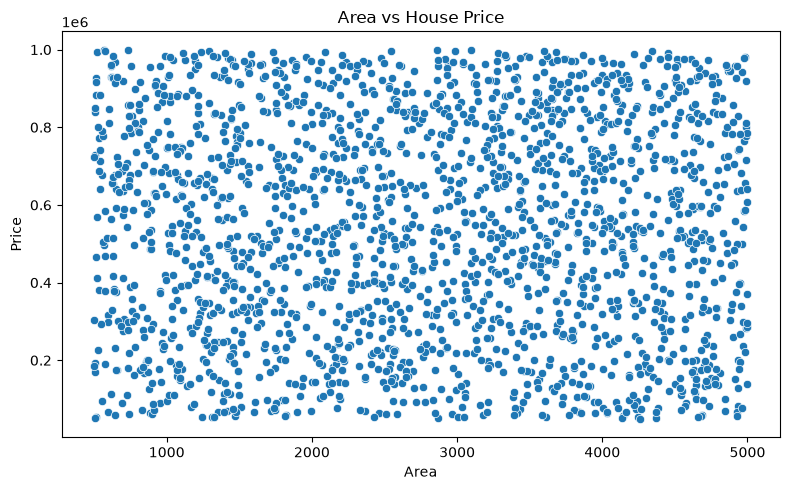

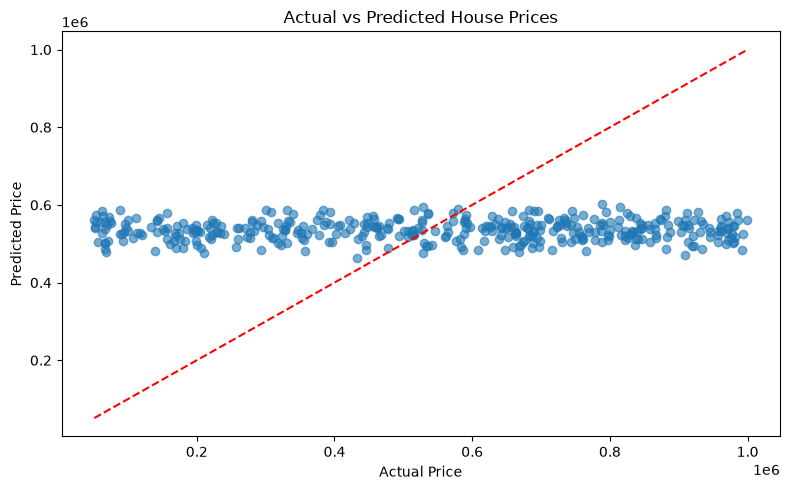

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Area vs Price
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Area", y="Price")
plt.title("Area vs House Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

# Actual vs Predicted Price
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.tight_layout()
plt.show()

In [10]:
# Check unique values and ranges
print("Price range:")
print("Minimum:", df["Price"].min())
print("Maximum:", df["Price"].max())

print("\nArea range:")
print("Minimum:", df["Area"].min())
print("Maximum:", df["Area"].max())

print("\nPrice by Location:")
print(df.groupby("Location_Rural")["Price"].mean())

print("\nPrice statistics by Area groups:")
print(df.groupby(pd.cut(df["Area"], bins=5))["Price"].agg(
    ["count", "mean", "std"]
))

Price range:
Minimum: 50005
Maximum: 999656

Area range:
Minimum: 501
Maximum: 4999

Price by Location:
Location_Rural
0    537385.780472
1    538613.943038
Name: Price, dtype: float64

Price statistics by Area groups:
                   count           mean            std
Area                                                  
(496.502, 1400.6]    382  535582.102094  278604.046562
(1400.6, 2300.2]     390  535433.746154  273625.822124
(2300.2, 3199.8]     383  528327.950392  270885.841476
(3199.8, 4099.4]     445  564316.074157  271748.644450
(4099.4, 4999.0]     400  521179.820000  286585.783263


In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate model
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Performance")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Model Performance
--------------------------------
MAE: 247761.03
RMSE: 285372.51
R2 Score: -0.0468


              Feature  Importance
0                Area    0.345215
4           YearBuilt    0.261638
1            Bedrooms    0.088920
2           Bathrooms    0.070596
3              Floors    0.049540
11         Garage_Yes    0.029562
8      Condition_Fair    0.027505
7      Location_Urban    0.027302
5      Location_Rural    0.027205
6   Location_Suburban    0.024572
9      Condition_Good    0.024435
10     Condition_Poor    0.023509


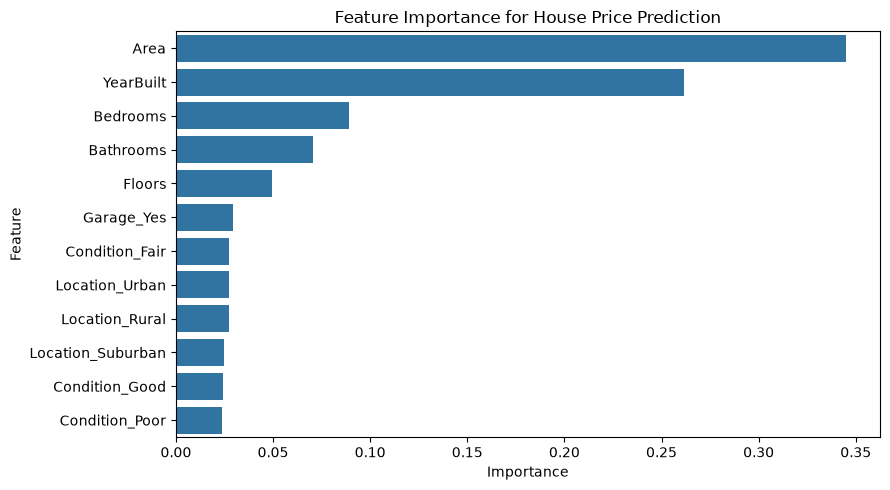

In [12]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance for House Price Prediction")
plt.tight_layout()
plt.show()

In [13]:
# Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print("Model Comparison:")
display(results.round(3))

# Save comparison results
results.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,243241.978,279859.726,-0.007
1,Random Forest,247761.030,285372.509,-0.047


Model comparison saved successfully!
